# Site percolation: message passing and Monte Carlo

**Internship at CoMuNe Lab** · Riccardo Corte · started on 9 October 2026

Goal O3 of the initial plan: solve the message passing equations
numerically on a given graph and compare the result with a Monte Carlo simulation on the same
network.


Structure: 1. networks; 2. message passing (fixed degree and full equation); 3. Monte Carlo;
4. applications at fixed φ and at varying φ, with the RMS deviation between the two methods;
5. node-dependent φ: targeted removal of the most connected nodes.

## 0. Setup

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
from math import comb


rng = np.random.default_rng(0)  # fixed seed, so that the results can be reproduced


## 1. Networks

`K4`, where the results are already known by hand, and three synthetic networks with `N = 1000` nodes.
For each one: construction, basic statistics and a drawing of the intact network.

In [2]:
# test network
# The first test network, used for the first analyses, is K4
# It is symmetric and already solved analytically

G = nx.Graph()
G.add_edges_from([(1,2), (1,3), (1,4), (2,3), (2,4), (3,4)])

print(list(G.neighbors(2)))

A = nx.to_numpy_array(G, nodelist = [1,2,3,4])
print(A)


[1, 3, 4]
[[0. 1. 1. 1.]
 [1. 0. 1. 1.]
 [1. 1. 0. 1.]
 [1. 1. 1. 0.]]


Three synthetic graphs with `N = 1000` nodes:

- **Random regular, degree 3**: every node has 3 neighbours as in `K4`, but the network is sparse.
- **Erdős-Rényi, mean degree 3**: same mean degree as the regular graph, but the degree changes from node to node.
- **Barabási-Albert, `m = 3`**: very heterogeneous degrees (hubs). `m = 3` is the value used in Artime
  and De Domenico (arXiv:2104.14893, Fig. 5); here the mean degree is about 6, not 3.

In [3]:
# --- parameters ---
N_big = 1000        # number of nodes of each graph
k_reg = 3           # degree of the regular graph: the same as K4
k_er = 3            # mean degree of the Erdos-Renyi graph: the same as the regular one
m_ba = 3            # links brought by each new node in the Barabasi-Albert graph

# --- the three graphs ---
grafi = {
    "regular": nx.random_regular_graph(k_reg, N_big, seed=1),
    "Erdos-Renyi": nx.gnp_random_graph(N_big, k_er / (N_big - 1), seed=1),
    "Barabasi-Albert": nx.barabasi_albert_graph(N_big, m_ba, seed=1),
}

# --- check: what we have built ---
for nome, g in grafi.items():
    gradi = [d for _, d in g.degree]
    lcc = max(nx.connected_components(g), key=len)
    print(nome)
    print("  nodes:", g.number_of_nodes(), " links:", g.number_of_edges())
    print("  mean degree:", np.mean(gradi), " min:", min(gradi), " max:", max(gradi))
    print("  connected:", nx.is_connected(g), " LCC/N with no removal:", len(lcc) / N_big)


regular
  nodes: 1000  links: 1500
  mean degree: 3.0  min: 3  max: 3
  connected: True  LCC/N with no removal: 1.0
Erdos-Renyi
  nodes: 1000  links: 1486
  mean degree: 2.972  min: 0  max: 9
  connected: False  LCC/N with no removal: 0.934
Barabasi-Albert
  nodes: 1000  links: 2991
  mean degree: 5.982  min: 1  max: 91
  connected: True  LCC/N with no removal: 1.0


In [4]:
# node positions for the drawings: slow to compute (about 30 s), to be run only once
posizioni = {nome: nx.spring_layout(g, seed=1) for nome, g in grafi.items()}


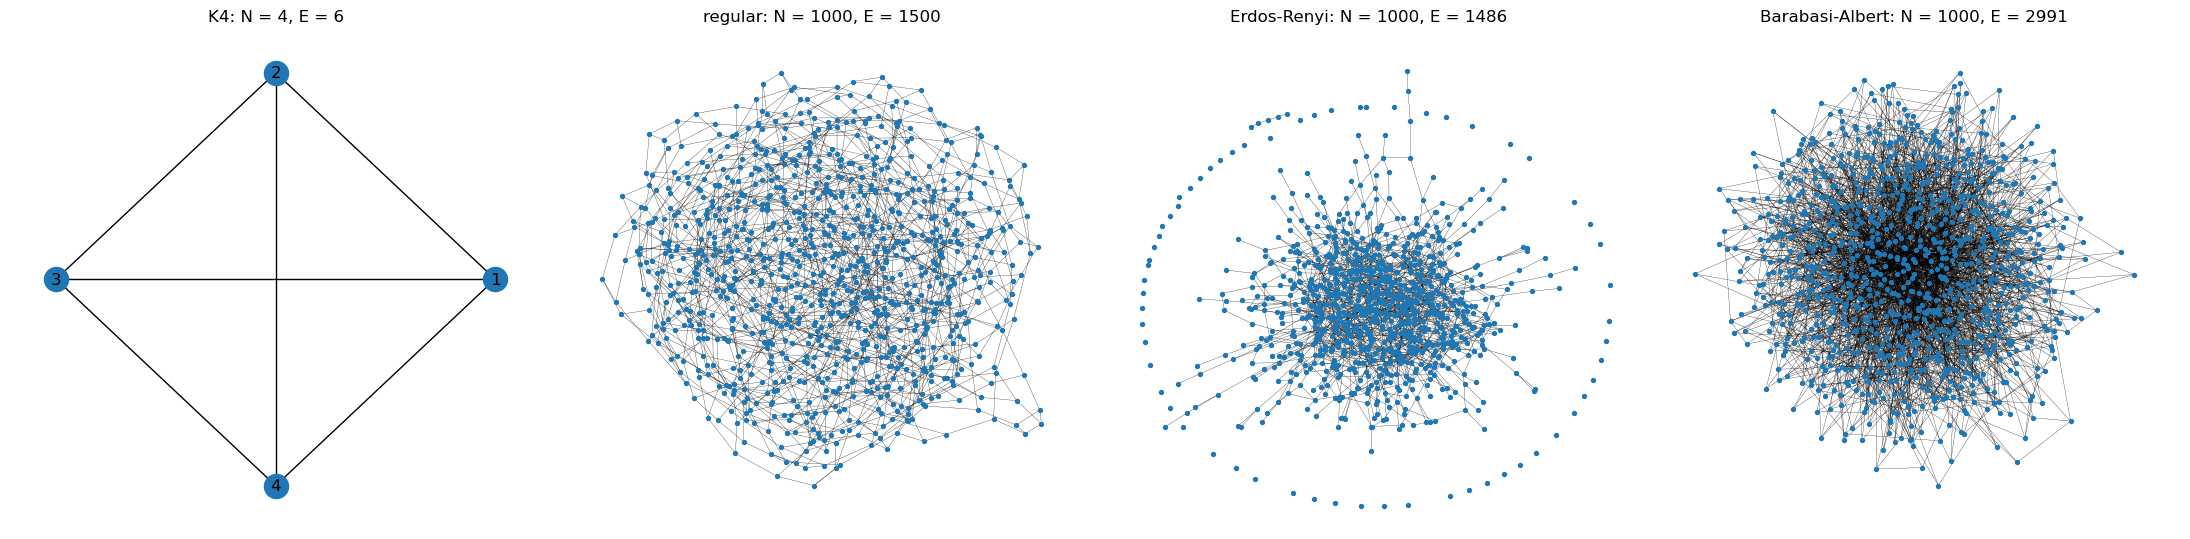

In [5]:
# drawing of the four intact networks; the dictionary reti is also used in the applications
reti = {"K4": G, **grafi}
pos_reti = {"K4": nx.circular_layout(G), **posizioni}

fig, assi = plt.subplots(1, 4, figsize=(22, 5.5))
for ax, (nome, g) in zip(assi, reti.items()):
    piccola = g.number_of_nodes() < 10          # K4: large nodes, with labels
    nx.draw_networkx(g, pos_reti[nome], ax=ax, node_size=300 if piccola else 8,
                     width=1 if piccola else 0.2, with_labels=piccola, node_color="tab:blue")
    ax.set_title(f"{nome}: N = {g.number_of_nodes()}, E = {g.number_of_edges()}")
    ax.axis("off")
plt.tight_layout()
plt.show()


## 2. Message passing

Two versions of eqs. 8.24-8.26 (course book v4, sec. 8.2.4, pp. 245-246): first the case where all
the messages are equal and the equation can be solved by hand, then the full equation, which works on any network.

### 2a. Fixed degree

If every node has 3 neighbours and `φ` is the same for all nodes, all the messages have the same value `t` and eq. 8.25
becomes `t = φ[1 − (1 − t)²]` (hand calculation of 9 October). It holds for `K4` and for the regular graph, not for ER and BA.

In [6]:
def S_mp_grado3(phi):
    """Message passing prediction when every node has 3 neighbours (hand calculation):
    S = phi [1 - (1/phi - 1)^3] above the threshold phi = 1/2, zero below."""
    phi = np.asarray(phi, dtype=float)
    S = np.zeros_like(phi)
    sopra = phi > 0.5                      # the formula holds only above the threshold
    S[sopra] = phi[sopra] * (1 - (1 / phi[sopra] - 1) ** 3)
    return S

# check against the value computed by hand: it must give 19/45 = 0.4222
print(S_mp_grado3(0.6), 19 / 45)


0.42222222222222217 0.4222222222222222


### 2b. Full equation

One message `t_{i→j}` for each direction of each link (`2|E|` unknowns), all updated together
starting from `t = 1` until convergence; then `s_i` (8.24) and `S_MP` (8.26). `φ` can be different from node to node.

In [7]:
def message_passing(G, phi, tol=1e-10, max_iter=10000):
    """Site percolation with message passing (course book v4, sec. 8.2.4, eqs. 8.24-8.26).

    phi: a number (the same for all nodes) or a dict {node: phi of that node}.
    Returns S_MP, s (dict node -> s_i), t (dict (i, j) -> t_{i->j}),
    the number of iterations used and whether the iteration has converged.
    """
    #if nx.number_of_selfloops(G) > 0:
    #    raise ValueError("the network has self-loops: against the assumptions of the model")

    nodi = list(G.nodes())
    phi_n = {n: phi for n in nodi} if np.isscalar(phi) else dict(phi)

    # 2|E| messages: two directions for each link
    messaggi = [(i, j) for i, j in G.edges()] + [(j, i) for i, j in G.edges()]  # the "+" joins the two lists: first the links in the direction given by G.edges(), then reversed

    # for each message i->j, the list of messages it has to read
    # (j->k with k in N_j \ {i}) is computed only once, outside the loop.
    # It is the row i->j of the matrix G from the notes of 8 October.
    # In practice, here we build the 0s and 1s of the matrix G
    da_leggere = {(i, j): [(j, k) for k in G.neighbors(j) if k != i] for (i, j) in messaggi}

    t = {m: 1.0 for m in messaggi}       # start far from t = 0, which is always a solution: starting from 0 we would stay there every time, starting from 1 we do not get stuck in it
    converge = False

    for it in range(1, max_iter + 1):
        # synchronous update: all the new messages from the old ones, t_{n+1} = F(t_n)
        t_new = {}
        for (i, j) in messaggi:
            prod = 1.0                   # empty product = 1: for a leaf j we get t_{i->j} = 0
            for m in da_leggere[(i, j)]:
                prod *= 1.0 - t[m]      # this is the product: no link leads to the GCC
            t_new[(i, j)] = phi_n[j] * (1.0 - prod)          # eq. 8.25: at least one leads to the GCC

        # we stop when no message changes by more than tol
        diff = max((abs(t_new[m] - t[m]) for m in messaggi), default=0.0)
        t = t_new
        if diff < tol:
            converge = True
            break

    # eq. 8.24: one s_i per node (an isolated node has an empty product, so s_i = 0)
    s = {}
    for i in nodi:
        prod = 1.0
        for j in G.neighbors(i):
            prod *= 1.0 - t[(i, j)]
        s[i] = phi_n[i] * (1.0 - prod)

    S_MP = sum(s.values()) / len(nodi)   # eq. 8.26, divided by all the N nodes as in mc_1run
    return S_MP, s, t, it, converge


Check on `K4` at `φ = 0.6`: it must give `t = 1/3` for all the 12 messages and `S = 19/45`, as in
the hand solution of section 2a.

In [8]:
# check on K4 at phi = 0.6 (hand calculation of 9 October): t = 1/3 for all the 12 messages, S = 19/45
S_MP, s, t, it, ok = message_passing(G, 0.6)
print(f"S_MP = {S_MP:.6f}  (expected {19/45:.6f}),  messages = {len(t)},  "
      f"values of t = {sorted(set(round(x, 10) for x in t.values()))},  iterations = {it}, converged = {ok}")


S_MP = 0.422222  (expected 0.422222),  messages = 12,  values of t = [0.3333333337],  iterations = 89, converged = True


## 3. Monte Carlo

One run: each node stays with probability `φ`, then we measure the fraction of nodes in the largest
connected component (proxy `Smax/N`, course book v4, p. 240).

In [9]:
def mc_1run(G, phi, rng):
    """One run of site percolation. Returns S^MC of that run.

    phi: a number (the same for all nodes) or a dict {node: phi of that node},
    as in message_passing.
    """
    nodi = list(G.nodes)
    N = len(nodi)

    # one phi per node, in the same order as nodi
    phi_n = np.full(N, phi) if np.isscalar(phi) else np.array([phi[n] for n in nodi])

    # one value per node: True (1) if the node stays, with its own probability phi
    presente = rng.random(N) < phi_n
    rimasti = [n for n, c in zip(nodi, presente) if c]

    # limit case: no node left
    if len(rimasti) == 0:
        return 0.0

    # graph with only the nodes left and the links between them
    H = G.subgraph(rimasti)

    # connected groups, sorted from the largest to the smallest
    gruppi = sorted(nx.connected_components(H), key=len, reverse=True)
    lcc = gruppi[0]

    return len(lcc) / N


Check: with `φ = 1` on `K4` we must get 1, with `φ = 0` we must get 0.

In [10]:
# test

print("No nodes removed: ", mc_1run(G, 1, rng))

print("All nodes removed: ", mc_1run(G, 0, rng))

l = np.linspace(0.3, 0.7, 5)

for i in range(len(l)):
    print("Intermediate value: ", l[i], mc_1run(G, l[i], rng))


No nodes removed:  1.0
All nodes removed:  0.0
Intermediate value:  0.3 0.25
Intermediate value:  0.39999999999999997 0.5
Intermediate value:  0.5 0.5
Intermediate value:  0.6 0.5
Intermediate value:  0.7 0.5


`curve_mc` repeats the runs on a grid of values of `φ` between 0 and 1: it is used for the curves of section 4.2.

In [11]:
def curve_mc(G, num_runs, num_phis, rng):
    """Monte Carlo curve on a graph: num_phis values of phi between 0 and 1, num_runs runs for each.
    Returns the values of phi and a matrix with one row per phi and one column per run."""
    phis = np.linspace(0, 1, num_phis)

    results = []

    for i in range(len(phis)):
        intermediate = []
        for k in range(num_runs):
            intermediate.append(mc_1run(G, phis[i], rng))
        results.append(intermediate)

    return phis, np.array(results)


## 4. Applications

Comparison on the four networks between Monte Carlo, the full message passing and, where the degree is 3,
the message passing solved by hand: first at fixed `φ`, then at varying `φ`.

### 4.1 Fixed φ

`φ = 0.6`, 200 Monte Carlo runs per network: distribution of `S` over the runs and its mean, then a table
that compares it with the message passing.

#### K4

In [12]:
# Actual MC run with 200 iterations for phi = 0.6

num = 200
phi = 0.6
results = []

for i in range(num):
    results.append(mc_1run(G, phi, rng))

r = np.array(results)
print(len(results))


200


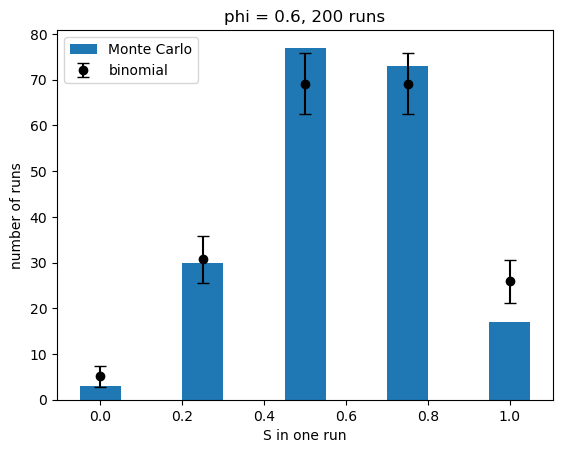

[0.   0.25 0.5  0.75 1.  ]
expected: [ 5.1 30.7 69.1 69.1 25.9]
error: [2.2 5.1 6.7 6.7 4.7]


In [13]:
# heights expected from the binomial (true only for a complete graph, where S = k/N)
N = G.number_of_nodes()
k = np.arange(N + 1)                      # number of survivors: 0, 1, ..., N
P = np.array([comb(N, i) * phi**i * (1 - phi)**(N - i) for i in k])
attese = num * P                          # expected height of each bar
errore = np.sqrt(num * P * (1 - P))       # expected fluctuation of the count

# observed counts
valori, conteggi = np.unique(results, return_counts=True)

plt.bar(valori, conteggi, width=0.1, label="Monte Carlo")
plt.errorbar(k / N, attese, yerr=errore, fmt="o", color="black", capsize=4,
             label="binomial")
plt.xlabel("S in one run")
plt.ylabel("number of runs")
plt.title(f"phi = {phi}, {num} runs")
plt.legend()
plt.show()

print(valori)
print("expected:", attese.round(1))
print("error:", errore.round(1))


**Result at φ = 0.6, 200 runs.** The mean of S^MC is within a few hundredths of 0.6 (it changes from
one execution to the next), which is the mean fraction of surviving nodes. K4 is fully connected: the nodes that survive are
always all linked to each other, so in every run S^MC is equal to the fraction of surviving
nodes.

In [14]:
# mean size of the surviving GCC:

SMC = np.average(results)
print("Mean fraction of the surviving GCC: ", SMC)


Mean fraction of the surviving GCC:  0.58875


It is interesting to approximate the idea that the GCC exists only when N goes to infinity. We try to do this by saying that components of 1 or 2 nodes are not considered: they are removed and count as zero in the mean.

This approximation gives a value that is closer, both physically and numerically, to the expected value of S from the message passing, which is about 0.42.

In [15]:
# runs with 2 surviving nodes or fewer (S < 0.75 on K4) count as zero
SMC_physical = np.mean(np.where(r >= 0.75, r, 0))
print("Mean fraction of the surviving GCC in the physical interpretation: ", SMC_physical)


Mean fraction of the surviving GCC in the physical interpretation:  0.35875


#### Networks with 1000 nodes

First a single run for each network, drawn: in blue the survivors in the largest component, in
orange the survivors outside it; the removed nodes are not drawn. Then 200 runs for each network.

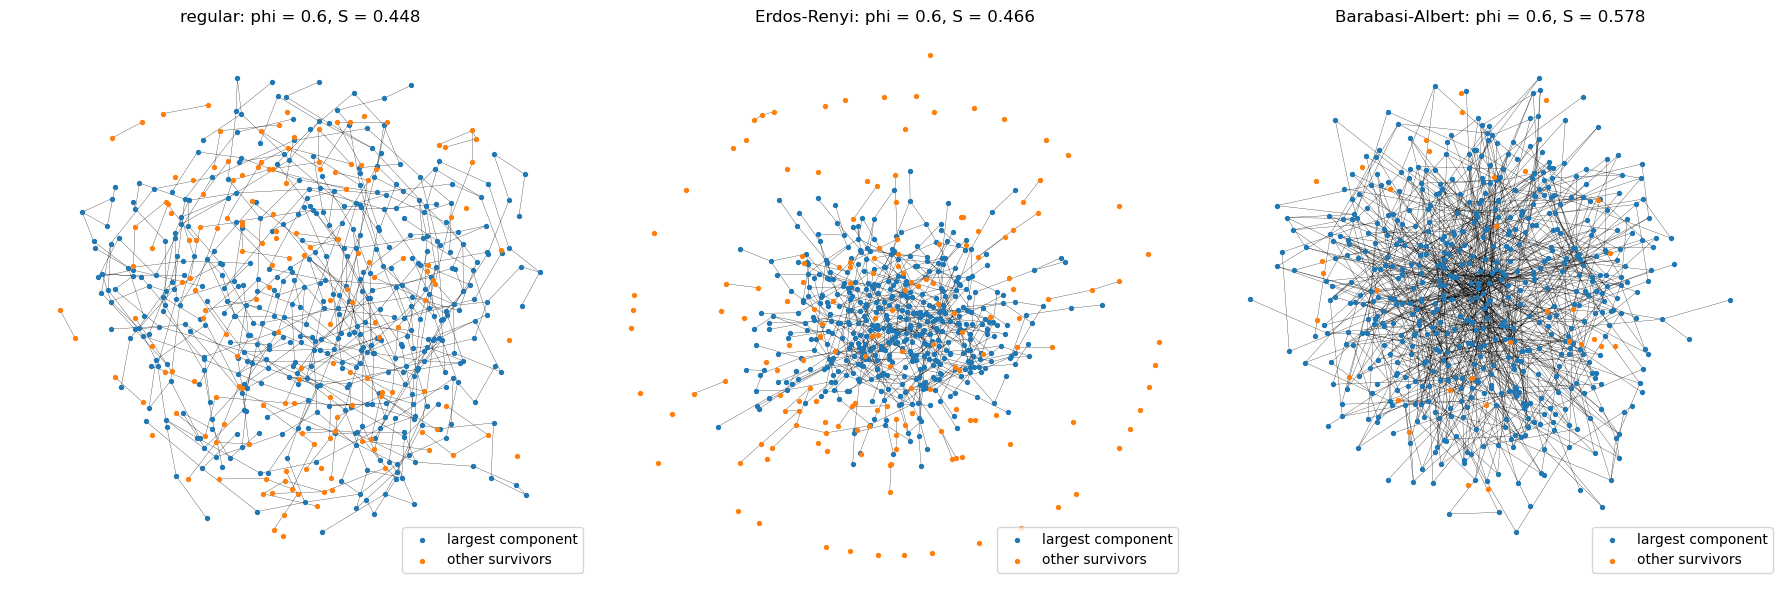

In [16]:
# one random removal at phi_disegno for each network (same extraction as in mc_1run);
# running the cell again changes the removal, the positions stay the same
phi_disegno = 0.6

fig, assi = plt.subplots(1, 3, figsize=(18, 6))
for ax, (nome, g) in zip(assi, grafi.items()):
    pos = posizioni[nome]
    nodi = list(g.nodes)
    presente = rng.random(len(nodi)) < phi_disegno
    rimasti = [n for n, c in zip(nodi, presente) if c]
    H = g.subgraph(rimasti)
    lcc = max(nx.connected_components(H), key=len)
    altri = [n for n in rimasti if n not in lcc]

    nx.draw_networkx_edges(H, pos, ax=ax, width=0.2)
    nx.draw_networkx_nodes(H, pos, ax=ax, nodelist=list(lcc), node_size=8,
                           node_color="tab:blue", label="largest component")
    nx.draw_networkx_nodes(H, pos, ax=ax, nodelist=altri, node_size=8,
                           node_color="tab:orange", label="other survivors")
    ax.set_title(f"{nome}: phi = {phi_disegno}, S = {len(lcc) / len(nodi):.3f}")
    ax.legend(loc="lower right")
    ax.axis("off")
plt.tight_layout()
plt.show()


With `N = 1000` the possible values of `S` are many, so
the histogram is made with bins (`plt.hist`) and not with separate bars as for `K4`.

regular  mean of S^MC: 0.41546500000000003


Erdos-Renyi  mean of S^MC: 0.43280500000000005


Barabasi-Albert  mean of S^MC: 0.577715


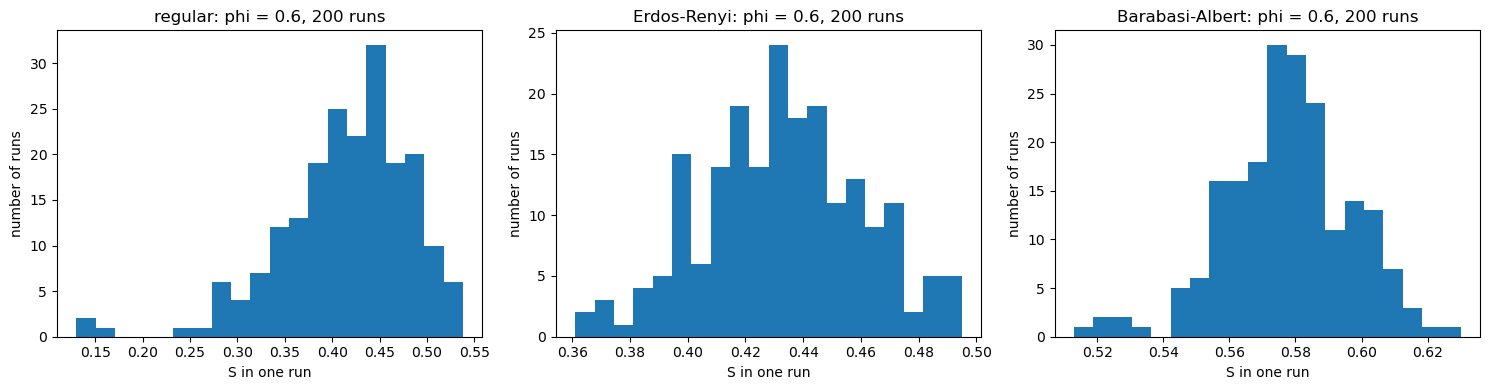

In [17]:
# Monte Carlo at fixed phi on the three graphs, with the same loop used for K4
num = 200
phi = 0.6

risultati = {}
for nome, g in grafi.items():
    r_g = []
    for i in range(num):
        r_g.append(mc_1run(g, phi, rng))
    risultati[nome] = np.array(r_g)
    print(nome, " mean of S^MC:", risultati[nome].mean())

# one histogram per graph, side by side
fig, assi = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nome, r_g) in zip(assi, risultati.items()):
    ax.hist(r_g, bins=20)
    ax.set_xlabel("S in one run")
    ax.set_ylabel("number of runs")
    ax.set_title(f"{nome}: phi = {phi}, {num} runs")
plt.tight_layout()
plt.show()


#### Summary at φ = 0.6

`19/45 ≈ 0.4222` is the exact solution of the message passing **only for the networks with degree 3** (`K4` and
the regular graph). For ER and BA there is no value computed by hand: we look at the agreement between message passing and
Monte Carlo. Monte Carlo is the reference (a direct estimate of `S` on the given network, with only a statistical
error); message passing is deterministic, with no noise, but it carries the systematic error of
its assumptions.

In [18]:
# comparison table at phi = 0.6 on the four networks
risultati["K4"] = r          # the 200 runs on K4 done above

righe = []
for nome, g in reti.items():
    S_c, _, _, it, ok = message_passing(g, phi)
    grado3 = all(d == 3 for _, d in g.degree)
    righe.append({"network": nome,
                  "S^MC": risultati[nome].mean(),
                  "S^MP full": S_c,
                  "S^MP by hand": float(S_mp_grado3(phi)) if grado3 else np.nan,
                  "iterations": it,
                  "converged": ok})

tabella = pd.DataFrame(righe).set_index("network")
tabella.round(4)


,S^MC,S^MP full,S^MP by hand,iterations,converged
network,,,,,
K4,0.5888,0.4222,0.4222,89,True
regular,0.4155,0.4222,0.4222,89,True
Erdos-Renyi,0.4328,0.4351,NaN,32,True
Barabasi-Albert,0.5777,0.5784,NaN,12,True


#### Comment at φ = 0.6

**Regular graph: Monte Carlo finds the message passing prediction.** At `φ = 0.6` the mean
over 200 runs is around 0.41-0.42, against `S^MP = 19/45 ≈ 0.4222` obtained by hand from eq. 8.25. On `K4`,
with the same equation, Monte Carlo gives about 0.6. Between the two cases only the network changes: same degree 3,
but `N = 1000` and a sparse structure. This is what we expected from the theory:

- with a large `N` the proxy `Smax/N` (course book v4, p. 240) really represents a giant component;
- in a sparse random graph the branches that start from a node are almost independent, as assumed by the
  product in eq. 8.25.

**Erdős-Rényi and Barabási-Albert.** The formula solved by hand does not hold (the degree changes from node to node):
the prediction is the one of the full solver, in the table above.

For ER and BA the construction parameters recall degree 3 (mean degree 3 for ER; 3 links for each
new node for BA, which however has mean degree about 6), but by construction the degrees are heterogeneous and
change from node to node (statistics of section 1). So the assumption that all the
messages `t` are equal, which allowed us to solve the fixed-degree equation by hand, no longer holds. What is left is the
full solver, which iterates eq. 8.25 on all the `2|E|` messages: its solution is in clear agreement
with Monte Carlo, which stays the reference for the size of the largest component.

### 4.2 Varying φ

Curve `S(φ)` on 41 values of `φ` between 0 and 1. Dots: Monte Carlo; line: full message passing;
dotted line: formula solved by hand (degree 3 only); dashed line: `S = φ`, the upper limit for both methods.

In [19]:
# Monte Carlo curves on the four networks: 41 values of phi (step 0.025, it includes 0.5 and 0.6)
num_phis = 41
prove = {"K4": 200, "regular": 50, "Erdos-Renyi": 50, "Barabasi-Albert": 50}

S_mc = {}
for nome, g in reti.items():
    phis, r_g = curve_mc(g, prove[nome], num_phis, rng)
    S_mc[nome] = r_g.mean(axis=1)           # mean over the runs, one value per phi


In [20]:
# curves of the full message passing on the same values of phi
# (close to the threshold the convergence slows down: the points that do not converge are reported)
S_mp = {}
for nome, g in reti.items():
    valori = []
    for p in phis:
        S_p, _, _, it, ok = message_passing(g, p)
        if not ok:
            print(f"{nome}, phi = {p:.3f}: does not converge in {it} iterations")
        valori.append(S_p)
    S_mp[nome] = np.array(valori)


K4, phi = 0.500: does not converge in 10000 iterations


regular, phi = 0.500: does not converge in 10000 iterations


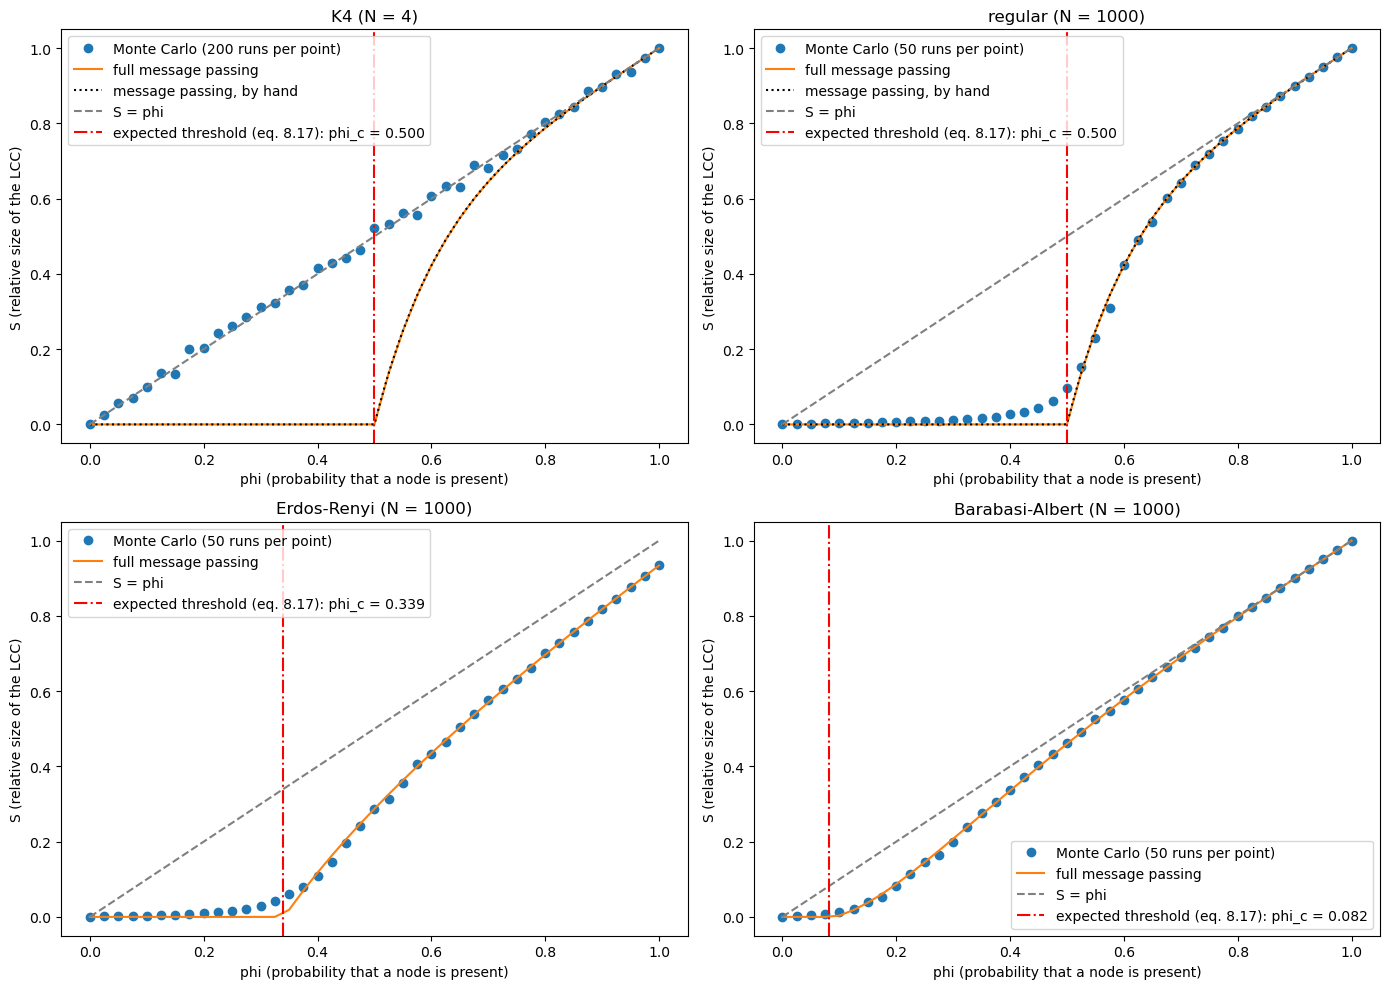

In [21]:
# comparison: one panel per network
phi_fine = np.linspace(0, 1, 400)

fig, assi = plt.subplots(2, 2, figsize=(14, 10))
for ax, (nome, g) in zip(assi.flat, reti.items()):
    ax.plot(phis, S_mc[nome], "o", label=f"Monte Carlo ({prove[nome]} runs per point)")
    ax.plot(phis, S_mp[nome], "-", label="full message passing")
    if all(d == 3 for _, d in g.degree):
        ax.plot(phi_fine, S_mp_grado3(phi_fine), ":", color="black", label="message passing, by hand")
    ax.plot(phi_fine, phi_fine, "--", color="gray", label="S = phi")
    # expected threshold from eq. 8.17, computed from the degrees of the network
    gradi = np.array([d for _, d in g.degree])
    phi_c = gradi.mean() / ((gradi ** 2).mean() - gradi.mean())
    ax.axvline(phi_c, color="red", linestyle="-.", label=f"expected threshold (eq. 8.17): phi_c = {phi_c:.3f}")
    ax.set_title(f"{nome} (N = {g.number_of_nodes()})")
    ax.set_xlabel("phi (probability that a node is present)")
    ax.set_ylabel("S (relative size of the LCC)")
    ax.legend()
plt.tight_layout()
plt.show()


#### Comment on the curves

In agreement with the table at `φ = 0.6`, Monte Carlo and message passing coincide on most of
the range of `φ`. The points to notice:

**No convergence at the threshold.** At `φ = 0.5` the solver does not converge in 10 000 iterations on `K4` and
on the regular graph. This is a good result: `φ = 1/2` is exactly the threshold predicted for degree 3
(`φc = 1/λmax`), and there the iteration slows down (critical slowing down). So the solver finds the
threshold in the point where the theory predicts it. For ER the threshold, about 1/3, does not fall on a point of the
grid of `φ`, so no point fails to converge.

**Lower threshold for BA.** By construction in BA hubs form right away, and they keep a giant
component together also at low `φ`. This is the "robust" side of the robust-yet-fragile behaviour
of heterogeneous networks (course book v4, sec. 8.2, p. 237): very robust to random failures, fragile to
attacks targeted at the hubs, which are not simulated here. In the Molloy-Reed criterion (pp. 238-239) the
threshold goes down when `⟨k²⟩` is large compared to `⟨k⟩`, as happens when there are hubs.

**Regular graph and `K4`.** The regular graph works much better than `K4` and in fact it matches
Monte Carlo. `K4` has two problems that the regular graph does not have: `N = 4`, while message passing is
defined in the limit `N → ∞`, and short cycles (the neighbours of each node are linked to each other, against
the assumption of independent branches), while the regular graph has no triangles. On `K4` the `S` of message passing is
far from the Monte Carlo one and gets close only for large `φ`.

**Remaining disagreement close to the threshold.** On the regular graph and on ER, below the threshold, Monte Carlo gives
small but non-zero values while message passing gives zero. It is a finite-size effect: in
a finite network the largest component below the threshold is small but not empty (sub-extensive, course book v4,
p. 65 and Tab. 3.1), while message passing, in the limit `N → ∞`, predicts exactly zero. Check in the cell
below: if `S^MC` goes to zero as `N` grows, the disagreement is due to the finite size.

Finite-size test: regular graph of degree 3 at `φ = 0.4` (below the threshold, where message
passing gives zero), mean of `S^MC` over 20 runs for increasing `N`.

In [22]:
# finite-size test below the threshold: S^MC must go to zero as N grows
phi_test = 0.4
num_test = 20

for N_test in [1000, 10_000, 100_000]:
    g = nx.random_regular_graph(3, N_test, seed=1)
    r_test = [mc_1run(g, phi_test, rng) for _ in range(num_test)]
    print(f"N = {N_test:>7}:  mean S^MC = {np.mean(r_test):.5f}   (message passing: 0)")


N =    1000:  mean S^MC = 0.02345   (message passing: 0)


N =   10000:  mean S^MC = 0.00499   (message passing: 0)


N =  100000:  mean S^MC = 0.00083   (message passing: 0)


### 4.3 RMS deviation between message passing and Monte Carlo

A single number for the agreement between the two curves `S(φ)` of section 4.2:
`sqrt( mean over φ of (S^MP(φ) − S^MC(φ))² )`, on all the 41 values of `φ` between 0 and 1,
including those where the solver does not converge.

In [23]:
def scarto_quadratico_medio(S_a, S_b):
    """Square root of the mean of the squared differences between two curves computed on the same phi."""
    differenze = np.asarray(S_a) - np.asarray(S_b)
    return np.sqrt(np.mean(differenze ** 2))


# one row per network, with the curves S_mp and S_mc of section 4.2
righe = []
for nome in reti:
    righe.append({"network": nome, "RMS deviation": scarto_quadratico_medio(S_mp[nome], S_mc[nome])})
pd.DataFrame(righe).set_index("network")


,RMS deviation
network,
K4,0.233041
regular,0.022273
Erdos-Renyi,0.012548
Barabasi-Albert,0.003889


## 5. Node-dependent φ: targeted removal of the most connected nodes

Until now `φ` was the same for all the nodes. Compared to the Generating Function method, message passing also works when every node has its own
`φ_i`, and this part of the code was never tested. Here we test it.

**How the `φ_i` are assigned.** By degree, as in the targeted attack of the course book (v4, eq. 8.18,
p. 244), in two steps:

1. the nodes are sorted from the most connected to the least connected, and the first ones of the list
   are removed with certainty (`φ_i = 0`). The percentage is a percentage of *all the nodes* of the
   network: with `N = 1000`, "top 5%" means the 50 nodes with the highest degree;
2. each of the other nodes stays with the same probability `φ`.

So `φ_i` takes two values, 0 for the removed nodes and `φ` for all the others. The Monte Carlo is still
random, and the curve `S(φ)` can be drawn as before, one curve for each percentage of removed nodes.

**What this means on the three networks.** In Barabási-Albert the removed nodes are real hubs. In
Erdős-Rényi there are no real hubs: the removed nodes just have a few more links than the others. In
the regular graph all the nodes have degree 3, so there is no "most connected" node and the removed
ones are simply the first of the list: it is the control case. This is a way to look at the "fragile"
side of the robust-yet-fragile behaviour.

### 5.1 Tools

`phi_mirato` builds the dictionary of the `φ_i`; `soglia_attesa` is eq. 8.17 computed on the network
without the removed nodes. `mc_1run` (section 3) accepts a dictionary, like `message_passing`.

In [ ]:
def phi_mirato(G, frazione, phi):
    """phi for each node in a targeted removal: the fraction `frazione` of nodes with the
    highest degree gets phi = 0, all the other nodes get phi.
    Returns the dict {node: phi of that node} and the list of the removed nodes."""
    # nodes from the most connected to the least connected
    # (nodes with the same degree keep the order of G.nodes)
    ordinati = sorted(G.nodes, key=lambda n: G.degree[n], reverse=True)

    num_tolti = int(round(frazione * G.number_of_nodes()))
    tolti = ordinati[:num_tolti]

    phi_n = {n: phi for n in G.nodes}
    for n in tolti:
        phi_n[n] = 0.0

    return phi_n, tolti


def soglia_attesa(G, tolti=()):
    """Expected threshold from eq. 8.17, computed from the degrees of the network
    that is left after taking away the nodes in `tolti`."""
    tolti = set(tolti)
    H = G.subgraph([n for n in G.nodes if n not in tolti])
    gradi = np.array([d for _, d in H.degree])
    return gradi.mean() / ((gradi ** 2).mean() - gradi.mean())


Checks. With a dictionary where all the `φ_i` are equal, the two functions must give the same result as
with a single number. With all the `φ_i = 1` except the removed nodes, the Monte Carlo is not random
any more and must give the largest component of the network without those nodes.

In [ ]:
# 1) message passing on K4 with a dict of equal phi: must give 19/45 as with the number 0.6
S_dict, _, _, _, _ = message_passing(G, {n: 0.6 for n in G.nodes})
print("message passing, K4, dict of 0.6:", round(S_dict, 6), " expected:", round(19 / 45, 6))

# 2) Monte Carlo on K4 with a dict: all 1 gives 1, all 0 gives 0
print("Monte Carlo, K4, dict of 1:", mc_1run(G, {n: 1.0 for n in G.nodes}, rng),
      "  dict of 0:", mc_1run(G, {n: 0.0 for n in G.nodes}, rng))

# 3) Barabasi-Albert, top 5% of the nodes by degree removed and phi = 1 for the others: no randomness left
g = grafi["Barabasi-Albert"]
phi_n, tolti = phi_mirato(g, 0.05, 1.0)
H = g.subgraph([n for n in g.nodes if n not in set(tolti)])
lcc = max(nx.connected_components(H), key=len)
print("removed nodes:", len(tolti), "  smallest degree among them:", min(g.degree[n] for n in tolti))
print("Monte Carlo:", mc_1run(g, phi_n, rng), "  largest component computed directly:", len(lcc) / g.number_of_nodes())


message passing, K4, dict of 0.6: 0.422222  expected: 0.422222
Monte Carlo, K4, dict of 1: 1.0   dict of 0: 0.0
removed nodes: 50   smallest degree among them: 16
Monte Carlo: 0.94   largest component computed directly: 0.94


### 5.2 What the removal does to the network

For each network and each percentage of removed nodes: how many nodes are removed, their degrees (from
the smallest to the largest), the largest degree left, the size of the largest component when all the
other nodes are present (`φ = 1`), and the threshold expected from eq. 8.17 on the network that is
left. `K4` is not used here: its four nodes all have the same degree.

In [ ]:
frazioni = [0.0, 0.01, 0.05, 0.10]       # fraction of all the nodes removed, starting from the most connected

righe = []
for nome, g in grafi.items():
    for fr in frazioni:
        _, tolti = phi_mirato(g, fr, 1.0)
        H = g.subgraph([n for n in g.nodes if n not in set(tolti)])
        lcc = max(nx.connected_components(H), key=len)
        righe.append({"network": nome,
                      "removed": "none" if fr == 0 else f"top {fr:.0%}",
                      "nodes removed": len(tolti),
                      "their degrees": "-" if fr == 0 else f"{min(g.degree[n] for n in tolti)} to {max(g.degree[n] for n in tolti)}",
                      "max degree left": max(d for _, d in H.degree),
                      "LCC/N at phi = 1": len(lcc) / g.number_of_nodes(),
                      "phi_c (eq. 8.17)": soglia_attesa(g, tolti)})

tabella_hub = pd.DataFrame(righe).set_index(["network", "removed"])
tabella_hub.round(3)


nodes removed their degrees  max degree left  \
network         removed                                                 
regular         none                 0             -                3   
                top 1%              10        3 to 3                3   
                top 5%              50        3 to 3                3   
                top 10%            100        3 to 3                3   
Erdos-Renyi     none                 0             -                9   
                top 1%              10        7 to 9                7   
                top 5%              50        6 to 9                6   
                top 10%            100        5 to 9                5   
Barabasi-Albert none                 0             -               91   
                top 1%              10      35 to 91               32   
                top 5%              50      16 to 91               14   
                top 10%            100      11 to 91               10   

                         LCC/N at phi = 1  phi_c (eq. 8.17)  
network         removed                                      
regular         none                1.000             0.500  
                top 1%              0.990             0.505  
                top 5%              0.950             0.527  
                top 10%             0.899             0.559  
Erdos-Renyi     none                0.934             0.339  
                top 1%              0.921             0.363  
                top 5%              0.858             0.442  
                top 10%             0.758             0.557  
Barabasi-Albert none                1.000             0.082  
                top 1%              0.989             0.137  
                top 5%              0.940             0.241  
                top 10%             0.848             0.363

**What the table says.** In Barabási-Albert the largest degree goes from 91 to 32 after removing only
the 10 most connected nodes (top 1%), and to 10 after removing the top 10%. The expected threshold
moves from 0.082 to 0.137, 0.241 and 0.363: with the top 10% removed it is more than four times
larger. In Erdős-Rényi it goes from 0.339 to 0.557, in the regular graph from 0.500 to 0.559.

In the regular graph the removed nodes are not more connected than the others (all the degrees are 3).
Its threshold moves a little anyway, because the neighbours of a removed node are left with 2 links
instead of 3.

### 5.3 Curves S(φ) for different percentages of removed nodes

For each network and each percentage: Monte Carlo (50 runs per point) and full message passing on 21
values of `φ`. `S` is always divided by all the `N` nodes of the original network. The curve with no
node removed is the one of section 4.2.

In [ ]:
# Monte Carlo and message passing with node-dependent phi
num_phis_mirato = 21                         # step 0.05
phis_mirato = np.linspace(0, 1, num_phis_mirato)
prove_mirato = 50

S_mc_mirato = {}
S_mp_mirato = {}
for nome, g in grafi.items():
    for fr in frazioni[1:]:                  # the case with no node removed is already in section 4.2
        valori_mc = []
        valori_mp = []
        for p in phis_mirato:
            phi_n, _ = phi_mirato(g, fr, p)
            valori_mc.append(np.mean([mc_1run(g, phi_n, rng) for _ in range(prove_mirato)]))
            S_p, _, _, it, ok = message_passing(g, phi_n)
            if not ok:
                print(f"{nome}, top {fr:.0%} removed, phi = {p:.2f}: does not converge in {it} iterations")
            valori_mp.append(S_p)
        S_mc_mirato[(nome, fr)] = np.array(valori_mc)
        S_mp_mirato[(nome, fr)] = np.array(valori_mp)


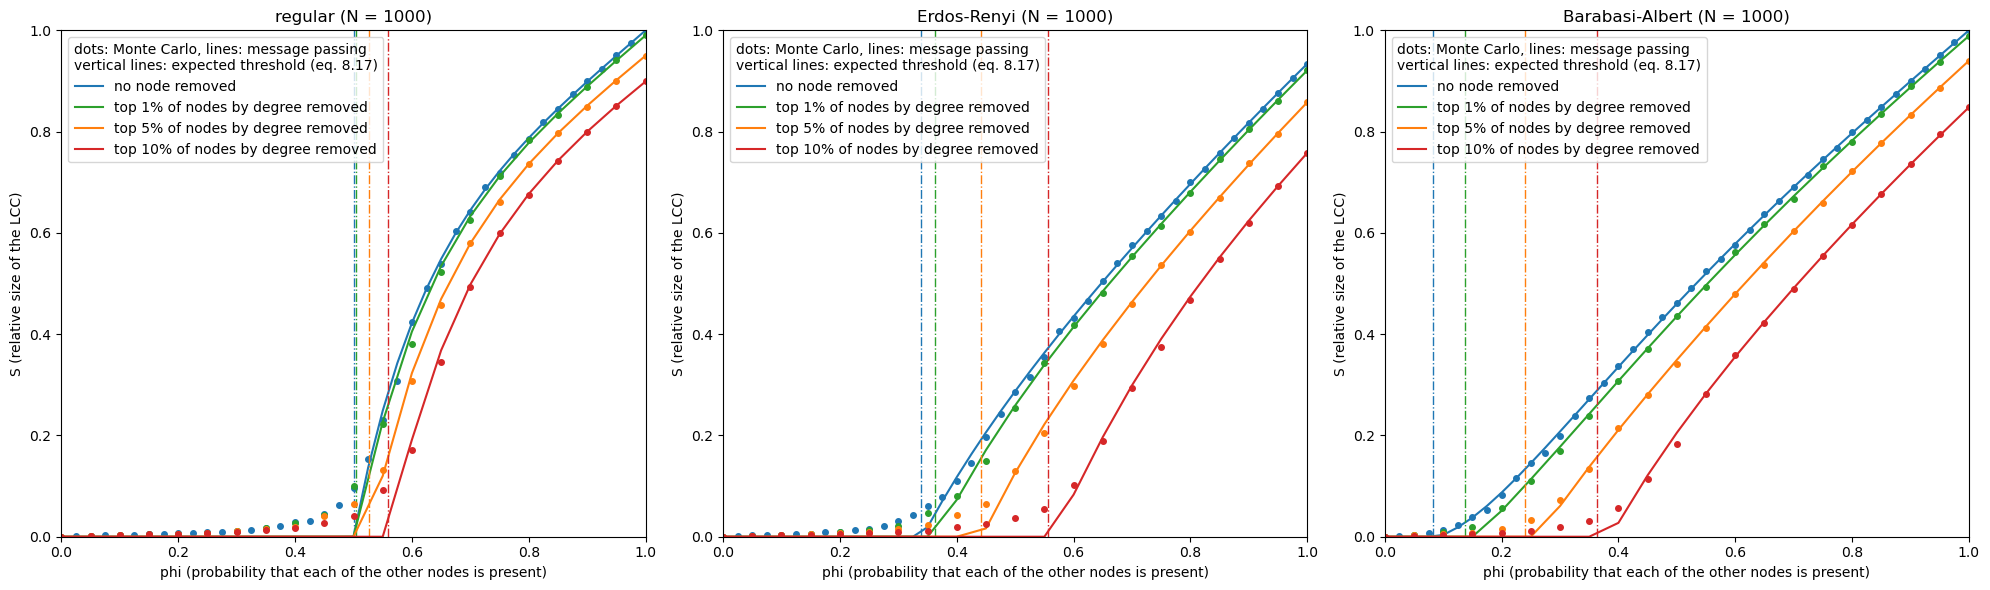

In [ ]:
# one panel per network, one colour per percentage of removed nodes
colori = {0.0: "tab:blue", 0.01: "tab:green", 0.05: "tab:orange", 0.10: "tab:red"}

fig, assi = plt.subplots(1, 3, figsize=(20, 6))
for ax, (nome, g) in zip(assi, grafi.items()):
    for fr in frazioni:
        if fr == 0.0:
            x, y_mc, y_mp = phis, S_mc[nome], S_mp[nome]              # curves of section 4.2
        else:
            x, y_mc, y_mp = phis_mirato, S_mc_mirato[(nome, fr)], S_mp_mirato[(nome, fr)]
        ax.plot(x, y_mc, "o", color=colori[fr], markersize=4)
        ax.plot(x, y_mp, "-", color=colori[fr],
                label="no node removed" if fr == 0.0 else f"top {fr:.0%} of nodes by degree removed")

        # expected threshold from eq. 8.17 on the network without the removed nodes
        _, tolti = phi_mirato(g, fr, 1.0)
        phi_c = soglia_attesa(g, tolti)
        if phi_c <= 1:
            ax.axvline(phi_c, color=colori[fr], linestyle="-.", linewidth=1)
    ax.set_title(f"{nome} (N = {g.number_of_nodes()})")
    ax.set_xlabel("phi (probability that each of the other nodes is present)")
    ax.set_ylabel("S (relative size of the LCC)")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.legend(title="dots: Monte Carlo, lines: message passing\nvertical lines: expected threshold (eq. 8.17)")
plt.tight_layout()
plt.show()


#### Comment on the curves

**Message passing follows Monte Carlo also with node-dependent `φ`.** For all the three networks and
all the percentages the lines pass through the dots on most of the range of `φ`. This is the first
test of the part of the solver that uses a different `φ_i` for each node.

**The threshold moves to the right when the most connected nodes are removed.** The more nodes are
removed, the larger the `φ` needed to have a giant component. The curves leave zero close to the
vertical lines of eq. 8.17 computed on the network without the removed nodes.

**The fragile side.** In Barabási-Albert the removal of a few hubs changes the picture much more than
in the regular graph, where the same number of removed nodes moves the curve only a little. In
relative terms the threshold of Barabási-Albert is the one that changes the most (table of section 5.2).
In absolute terms, with the top 10% removed its threshold (0.363) is still lower than the one of
Erdős-Rényi (0.557).

**Close to the threshold** the Monte Carlo dots are above the message passing line, as in section 4.2:
small but non-zero values where message passing gives zero. With the top 10% removed this region is
wider. In section 4.2 this was a finite-size effect; here it has not been checked with larger networks.

`S` at `φ = 1` is lower than 1 when nodes are removed: the removed nodes count in `N` but can never be
part of the largest component.

### 5.4 Fixed φ = 0.6, top 5% of the nodes by degree removed

200 Monte Carlo runs for each network: distribution of `S` over the runs, with the message passing value
as a vertical line. The three histograms use the same range on the x axis.

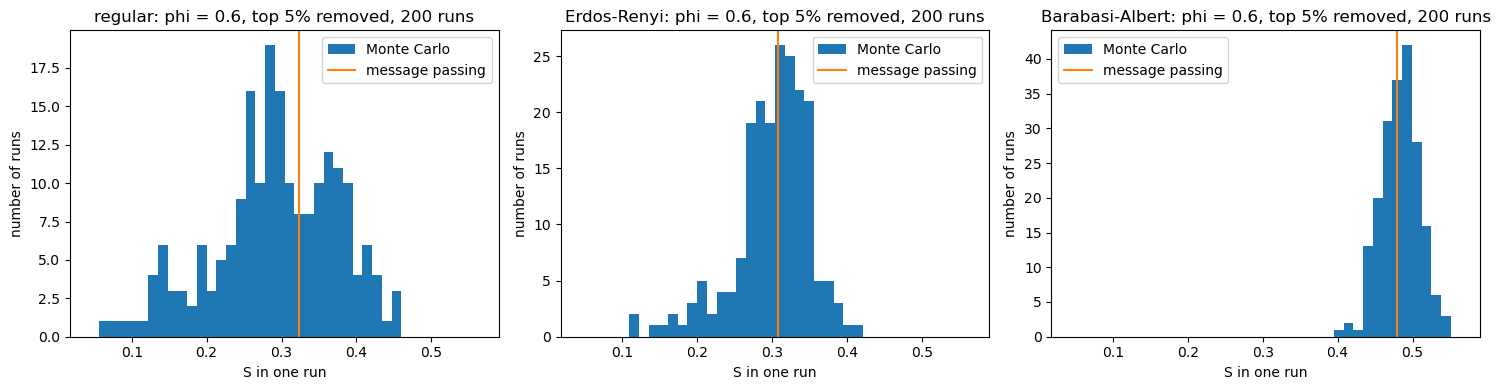

In [ ]:
num = 200
phi = 0.6
fr = 0.05

r_mirato = {}
S_mp_fisso = {}
for nome, g in grafi.items():
    phi_n, _ = phi_mirato(g, fr, phi)
    r_mirato[nome] = np.array([mc_1run(g, phi_n, rng) for _ in range(num)])
    S_mp_fisso[nome], _, _, _, _ = message_passing(g, phi_n)

# same x range for the three histograms
tutti = np.concatenate(list(r_mirato.values()) + [np.array(list(S_mp_fisso.values()))])
x_min, x_max = tutti.min() - 0.02, tutti.max() + 0.02

fig, assi = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
for ax, (nome, r_g) in zip(assi, r_mirato.items()):
    ax.hist(r_g, bins=40, range=(x_min, x_max), label="Monte Carlo")
    ax.axvline(S_mp_fisso[nome], color="tab:orange", label="message passing")
    ax.set_xlabel("S in one run")
    ax.set_ylabel("number of runs")
    ax.set_title(f"{nome}: phi = {phi}, top {fr:.0%} removed, {num} runs")
    ax.legend()
plt.tight_layout()
plt.show()


In [ ]:
# comparison table at phi = 0.6: with no node removed (section 4.1) and with the top 5% removed
righe = []
for nome, g in grafi.items():
    _, tolti = phi_mirato(g, fr, phi)
    righe.append({"network": nome,
                  "S^MC, no node removed": risultati[nome].mean(),
                  "S^MC, top 5% removed": r_mirato[nome].mean(),
                  "S^MP, top 5% removed": S_mp_fisso[nome],
                  "phi_c, no node removed": soglia_attesa(g),
                  "phi_c, top 5% removed": soglia_attesa(g, tolti)})
pd.DataFrame(righe).set_index("network").round(4)


,"S^MC, no node removed","S^MC, top 5% removed","S^MP, top 5% removed","phi_c, no node removed","phi_c, top 5% removed"
network,,,,,
regular,0.4155,0.2922,0.3232,0.5000,0.5271
Erdos-Renyi,0.4328,0.3004,0.3085,0.3386,0.4422
Barabasi-Albert,0.5777,0.4830,0.4796,0.0818,0.2406


#### Comment at φ = 0.6

With the top 5% of the nodes removed `S` goes down on all the three networks, and message passing
stays close to the mean of Monte Carlo: 0.309 against 0.300 on Erdős-Rényi and 0.480 against 0.483 on
Barabási-Albert.

On the regular graph the difference is larger, 0.323 against 0.292, and the histogram is much wider
than the other two. Here `φ = 0.6` is close to the expected threshold (0.527), where the size of the
largest component changes a lot from one run to the next.

### 5.5 RMS deviation with node-dependent φ

Same measure as in section 4.3, for each network and each percentage of removed nodes, on the 21 values of `φ`.

In [ ]:
righe = []
for nome in grafi:
    riga = {"network": nome}
    for fr in frazioni[1:]:
        riga[f"top {fr:.0%} removed"] = scarto_quadratico_medio(S_mp_mirato[(nome, fr)], S_mc_mirato[(nome, fr)])
    righe.append(riga)
pd.DataFrame(righe).set_index("network").round(4)


,top 1% removed,top 5% removed,top 10% removed
network,,,
regular,0.0257,0.0185,0.0245
Erdos-Renyi,0.0133,0.0164,0.0176
Barabasi-Albert,0.0057,0.0089,0.0122


The RMS deviation stays of the same order as in section 4.3 (0.022, 0.013 and 0.004 with no node
removed): between 0.006 and 0.026 for all the networks and all the percentages. It grows a little with
the percentage of removed nodes on Erdős-Rényi and Barabási-Albert.

## 6. Critical threshold from the largest eigenvalue of G

Near `t = 0` the message passing becomes linear, `t = φ G t`, and for the same `φ` on all the nodes the
threshold is `φ_c = 1/λ_max`, with `λ_max` the largest eigenvalue of `G` (course book v4, p. 246; notes,
Steps 5-7). `G` has `2|E|` rows but only `Σ_j k_j (k_j - 1)` ones, so we store it as a sparse matrix.

### 6.1 Building G

Same logic as `da_leggere` in `message_passing`: the row `i→j` has a 1 in the columns `j→k` for every
neighbour `k` of `j` other than `i`. Instead of a dict of lists we save the position of each 1
(row number, column number) and give the two lists to `scipy.sparse`.

In [ ]:
import scipy.sparse as sp
from scipy.sparse.linalg import eigs


def matrice_G(G):
    """Matrix G of the linearised message passing (notes, Step 5; course book v4, p. 246).
    Rows and columns are the 2|E| messages; G[i->j, j->k] = 1 for every k in N_j other than i.
    Returns G as a sparse CSR matrix and the list of the messages, in the order of the rows."""
    messaggi = [(i, j) for i, j in G.edges()] + [(j, i) for i, j in G.edges()]   # same order as in message_passing
    indice = {m: n for n, m in enumerate(messaggi)}     # message -> its row (and column) number

    righe, colonne = [], []
    for (i, j) in messaggi:
        for k in G.neighbors(j):          # the same loop as da_leggere
            if k != i:
                righe.append(indice[(i, j)])
                colonne.append(indice[(j, k)])

    M = len(messaggi)
    valori = np.ones(len(righe))          # all ones, as floats: eigs works with floating point numbers
    G_mat = sp.csr_matrix((valori, (righe, colonne)), shape=(M, M))
    return G_mat, messaggi


Checks on `K4`: 12 messages, each row has `k_j - 1 = 2` ones, so 24 ones in total, and the rows must be
the same as the lists of `da_leggere`. On the three graphs the number of ones must be `Σ_j k_j (k_j - 1)`.

In [ ]:
G_K4, msg_K4 = matrice_G(G)
print("K4: shape", G_K4.shape, " ones:", G_K4.nnz, " row sums:", set(G_K4.sum(axis=1).A1))

# row i->j of G against the list da_leggere of message_passing
da_leggere = {(i, j): [(j, k) for k in G.neighbors(j) if k != i] for (i, j) in msg_K4}
uguali = all(sorted(msg_K4[c] for c in G_K4[r].indices) == sorted(da_leggere[m]) for r, m in enumerate(msg_K4))
print("rows equal to da_leggere:", uguali)

for nome, g in grafi.items():
    G_mat, _ = matrice_G(g)
    gradi = np.array([d for _, d in g.degree])
    print(f"{nome}: shape {G_mat.shape}, ones {G_mat.nnz}, sum k(k-1) = {(gradi * (gradi - 1)).sum()}")


K4: shape (12, 12)  ones: 24  row sums: {np.float64(2.0)}
rows equal to da_leggere: True
regular: shape (3000, 3000), ones 6000, sum k(k-1) = 6000
Erdos-Renyi: shape (2972, 2972), ones 8778, sum k(k-1) = 8778
Barabasi-Albert: shape (5982, 5982), ones 73160, sum k(k-1) = 73160


### 6.2 Largest eigenvalue

`eigs` (ARPACK) finds a few eigenvalues by multiplying the matrix by vectors, without diagonalising it, so
the cost grows with the number of ones and not with `(2|E|)^2`. `G` is not symmetric, so `eigsh` cannot be
used. `which="LR"` asks for the largest real part: `G` has no negative entries, so by Perron-Frobenius the
largest eigenvalue is real; with `which="LM"` (largest modulus) a bipartite graph would also have `-λ_max`.

In [ ]:
def lambda_max(G_mat):
    """Largest eigenvalue of the sparse matrix G (scipy.sparse.linalg.eigs, ARPACK)."""
    val = eigs(G_mat, k=1, which="LR", return_eigenvectors=False)
    return val[0].real


Checks: on `K4` we must get `λ_max = 2` (notes, threshold of `K4`), the same as the full diagonalisation with
numpy; on the regular graph of degree 3 also 2, since every row sums to `k - 1 = 2`.

In [ ]:
print("K4, eigs :", lambda_max(G_K4))
print("K4, numpy:", max(np.linalg.eigvals(G_K4.toarray()).real))
print("regular  :", lambda_max(matrice_G(grafi["regular"])[0]))


K4, eigs : 2.000000000000001
K4, numpy: 2.0000000000000018
regular  : 2.0000000000000013


### 6.3 Comparison with the thresholds found before

The same cases as the table of section 5.2: no node removed and the top 1%, 5%, 10% removed. A removed node
has `φ_i = 0`, which is the same as taking it out of the network, so `G` is built on the graph that is left.
`φ_c (eq. 8.17)` is `soglia_attesa`, the value in the tables of sections 5.2 and 5.4.

In [ ]:
righe = []
for nome, g in reti.items():
    for fr in (frazioni if nome != "K4" else [0.0]):
        _, tolti = phi_mirato(g, fr, 1.0)
        H = g.subgraph([n for n in g.nodes if n not in set(tolti)])
        lam = lambda_max(matrice_G(H)[0])
        righe.append({"network": nome,
                      "removed": "none" if fr == 0 else f"top {fr:.0%}",
                      "lambda_max": lam,
                      "phi_c = 1/lambda_max": 1 / lam,
                      "phi_c (eq. 8.17)": soglia_attesa(g, tolti)})

tabella_lambda = pd.DataFrame(righe).set_index(["network", "removed"])
tabella_lambda["difference"] = tabella_lambda["phi_c = 1/lambda_max"] - tabella_lambda["phi_c (eq. 8.17)"]
tabella_lambda.round(4)


lambda_max  phi_c = 1/lambda_max  phi_c (eq. 8.17)  \
network         removed                                                       
K4              none         2.0000                0.5000            0.5000   
regular         none         2.0000                0.5000            0.5000   
                top 1%       1.9809                0.5048            0.5048   
                top 5%       1.8969                0.5272            0.5271   
                top 10%      1.7858                0.5600            0.5591   
Erdos-Renyi     none         2.9310                0.3412            0.3386   
                top 1%       2.7277                0.3666            0.3628   
                top 5%       2.2563                0.4432            0.4422   
                top 10%      1.7668                0.5660            0.5566   
Barabasi-Albert none        10.7450                0.0931            0.0818   
                top 1%       6.3383                0.1578            0.1370   
                top 5%       3.7884                0.2640            0.2406   
                top 10%      2.5859                0.3867            0.3631   

                         difference  
network         removed              
K4              none        -0.0000  
regular         none         0.0000  
                top 1%       0.0000  
                top 5%       0.0001  
                top 10%      0.0008  
Erdos-Renyi     none         0.0026  
                top 1%       0.0038  
                top 5%       0.0010  
                top 10%      0.0094  
Barabasi-Albert none         0.0113  
                top 1%       0.0208  
                top 5%       0.0234  
                top 10%      0.0236

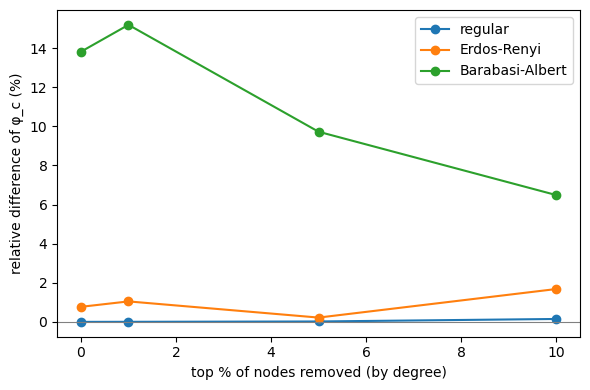

In [ ]:
# relative difference of the two thresholds, in percent of the generating-function value
diff_rel = 100 * tabella_lambda["difference"] / tabella_lambda["phi_c (eq. 8.17)"]
percentuali = [100 * fr for fr in frazioni]

fig, ax = plt.subplots(figsize=(6, 4))
for nome in ["regular", "Erdos-Renyi", "Barabasi-Albert"]:
    ax.plot(percentuali, diff_rel.loc[nome].values, "o-", label=nome)
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("top % of nodes removed (by degree)")
ax.set_ylabel("relative difference of φ_c (%)")
ax.legend()
plt.tight_layout()
plt.show()


**Relative difference.** In absolute terms the gap between the two thresholds grows as we remove the hubs
(Barabási-Albert: from 0.011 to 0.024), but the thresholds grow faster, so relative to the threshold the gap
gets smaller: from 14% to 7%, after a small rise at the top 1%. On the regular graph and on Erdős-Rényi it stays
below 2%. The main difference comes from the type of graph, not from the removal; section 6.4 looks at why.

### 6.4 Eigenvalue against generating functions as the size of the graph changes

For each `N`, one graph per type (same parameters as section 1). Columns:
- `lambda GF` is `<k²>/<k> - 1`, the eigenvalue that eq. 8.17 implies (`φ_c = 1/lambda GF`);
- `r` is the degree assortativity (`nx.degree_assortativity_coefficient`): 0 means no correlation between
  the degrees at the two ends of a link, negative means that hubs tend to be linked to small nodes;
- `lambda_max rewired` is `λ_max` after shuffling the links with `nx.double_edge_swap`, which keeps the degree
  of every node but destroys the correlations.

Running time: about two minutes, most of it for `N = 30000`.

In [ ]:
dimensioni = [1000, 3000, 10000, 30000]

def genera(tipo, N, seed):
    if tipo == "regular":
        return nx.random_regular_graph(k_reg, N, seed=seed)
    if tipo == "Erdos-Renyi":
        return nx.gnp_random_graph(N, k_er / (N - 1), seed=seed)
    return nx.barabasi_albert_graph(N, m_ba, seed=seed)

righe = []
for tipo in grafi:
    for N in dimensioni:
        g = genera(tipo, N, seed=1)
        gradi = np.array([d for _, d in g.degree])
        lam_gf = (gradi ** 2).mean() / gradi.mean() - 1 # eq 8.17
        lam = lambda_max(matrice_G(g)[0])

        g_rim = g.copy()      # same degrees, links shuffled
        nx.double_edge_swap(g_rim, nswap=10 * g.number_of_edges(), max_tries=100 * g.number_of_edges(), seed=2)

        righe.append({"network": tipo, "N": N,
                      "k max": gradi.max(),
                      "r": nx.degree_assortativity_coefficient(g) if tipo != "regular" else np.nan,
                      "lambda GF": lam_gf,
                      "lambda_max": lam,
                      "lambda_max rewired": lambda_max(matrice_G(g_rim)[0]),
                      "relative difference": (lam - lam_gf) / lam_gf})

tabella_N = pd.DataFrame(righe).set_index(["network", "N"])
tabella_N.round(3)


k max      r  lambda GF  lambda_max  \
network         N                                            
regular         1000       3    NaN      2.000       2.000   
                3000       3    NaN      2.000       2.000   
                10000      3    NaN      2.000       2.000   
                30000      3    NaN      2.000       2.000   
Erdos-Renyi     1000       9 -0.023      2.954       2.931   
                3000      11 -0.005      2.989       2.999   
                10000     11 -0.006      2.998       2.978   
                30000     12 -0.002      2.993       2.990   
Barabasi-Albert 1000      91 -0.057     12.230      10.745   
                3000     139 -0.049     14.066      12.178   
                10000    226 -0.042     16.679      13.849   
                30000    393 -0.031     18.802      15.407   

                       lambda_max rewired  relative difference  
network         N                                               
regular         1000                2.000                0.000  
                3000                2.000                0.000  
                10000               2.000                0.000  
                30000               2.000               -0.000  
Erdos-Renyi     1000                2.950               -0.008  
                3000                2.979                0.003  
                10000               3.009               -0.006  
                30000               2.999               -0.001  
Barabasi-Albert 1000               11.506               -0.121  
                3000               12.906               -0.134  
                10000              15.865               -0.170  
                30000              17.102               -0.181

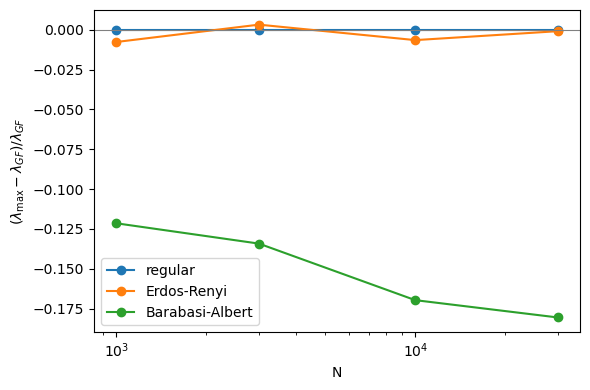

In [ ]:
# relative difference between lambda_max and the generating functions, one line per network
fig, ax = plt.subplots(figsize=(6, 4))
for tipo in grafi:
    ax.plot(dimensioni, tabella_N.loc[tipo, "relative difference"], "o-", label=tipo)
ax.axhline(0, color="gray", lw=0.8)
ax.set_xscale("log")
ax.set_xlabel("N")
ax.set_ylabel(r"$(\lambda_{\max} - \lambda_{GF}) / \lambda_{GF}$")
ax.legend()
plt.tight_layout()
plt.show()


#### Comment on section 6

**Goal.** This section explains why we use `λ_max` to find the critical threshold `φ_c`, the probability of
keeping a node above which a giant component exists (below it the network breaks into small pieces). We
built the matrix `G` of the linearised message passing, which is very large but sparse, and found its largest
eigenvalue with `scipy.sparse.linalg.eigs`; then `φ_c = 1/λ_max`. On Barabási-Albert this value does not agree
with the threshold of the generating functions (eq. 8.17), and here we look for the reason.

**Hypotheses of the two methods.** Both methods assume that the nodes are removed independently of each other
and that the branches leaving a node are independent (no short loops). Eq. 8.17 adds two more hypotheses: it
only uses the degree distribution `p_k` (the fraction of nodes with degree `k`), through `<k>` and `<k²>`, and
it assumes that there are no correlations between the degrees of linked nodes. `λ_max` is computed on the exact
network, so it does not need these two.

**Regular and Erdős-Rényi.** The two methods give the same threshold on the regular graph and differences below
2%, with random sign, on Erdős-Rényi (tables 6.3 and 6.4). Both graphs satisfy the extra hypotheses: in the
regular graph all the nodes have the same degree, so there is nothing to correlate, and in Erdős-Rényi the links
are placed at random.

**Barabási-Albert.** Here `λ_max` is clearly lower than the eigenvalue implied by the generating functions,
`<k²>/<k> - 1`: 10.75 against 12.23 with `N = 1000`. A lower eigenvalue means a higher threshold, 0.093 against
0.082 (table 6.3): the network is less robust to random removals than the generating functions predict, so
they are too optimistic. This is not an effect of a small `N`: the relative difference goes from -12% at
`N = 1000` to -18% at `N = 30000` (table 6.4 and plot), so a larger network makes it more visible, not smaller.

**Why: disassortativity.** A network is *disassortative* when nodes with high degree tend to be linked to nodes
with low degree (course book v4, sec. 7.1.1, pp. 204-208); the assortativity coefficient `r` is then negative,
as in our Barabási-Albert graphs (`r` between -0.06 and -0.03). The reason is the way the graph grows: each new
node brings `m = 3` links to existing nodes chosen in proportion to their degree. The hubs are the oldest nodes
and their links come mostly from newer nodes, which have a small degree; two hubs are linked only if one of
them chose the other when it was new. Eq. 8.17 assumes instead that the node reached at the next step does not
depend on where we come from, so it counts chains hub → hub → hub that are rare in the real graph, and it
overestimates the eigenvalue.

**Check: rewiring.** `nx.double_edge_swap` shuffles the links keeping the degree of every node, so the
correlations are destroyed: the hubs are now linked to nodes chosen at random, other hubs included. After the
shuffle `λ_max` moves towards the value of the generating functions: at `N = 30000` from 15.41 to 17.10, against
18.80, so the gap goes from -18% to -9%; at `N = 1000` from -12% to -6%. About half of the gap is due to the
correlations that the shuffle removes; the cause of the rest is still open.

**Removing the hubs (table 6.3).** On Barabási-Albert the absolute difference between the two thresholds grows
from 0.011 to 0.024 when we remove the top 10% of the nodes, but the thresholds themselves grow even more. In
relative terms the difference goes from 14% (none removed) to 15%, 10% and 7% (top 1%, 5%, 10%): once the
largest hubs are gone (the largest degree left goes from 91 to 10, table 5.2) the two methods get closer, which
is consistent with the explanation above.

**Conclusion.** From now on we use `φ_c = 1/λ_max`: it works on the real network and does not assume the absence
of degree correlations. The generating functions remain a quick first estimate, since they only need `<k>` and
`<k²>`, useful when `G` is too large to be built.